# Pan-human marker set (`marker_panhuman`)

A marker set for human maps derived from the **pan-human consensus map**: proteins that the
consensus map places confidently in **one** compartment of the coarse UniProt
subcellular-location vocabulary.

It complements the literature-curated panels in `hsap_markers.tsv`. Those are small and their
compartments differ between authors; this one is large (about 3,300 proteins), uses the same
compartment names as `gr.ds.gene_sets_curated` / `gr.tl.independent_diffusion`, and includes
compartments the curated panels lack (nucleolus, proteasome, the ribosomal subunits).

## Rule

The pan-human map is annotated with `gr.tl.independent_diffusion` (coarse UniProt vocabulary,
likelihood resolver). A protein becomes a marker of its resolved call `X` when

1. the calibrated probability of `X` is at least `MIN_CALL_PROBABILITY`;
2. no other term has a probability above `MAX_OTHER_PROBABILITY`, **ignoring expected
   co-annotations of `X`**: a term `Y` is ignored when at least `COANNOTATION_EXEMPT` of the
   proteins annotated `X` in the map are also annotated `Y` (computed from the vocabulary, not
   from the map). This exempts containers and systematic double annotations, e.g. nucleus for
   nucleolus, cytoplasm for the proteasome, nucleolus for the 40S ribosomal subunit;
3. nucleus and cytoplasm are held to a stricter `MAX_NUCLEUS_CYTOPLASM` against each other,
   because that pair is the most common genuine dual localisation;
4. cytoplasm is additionally ignored for the two endosome terms (`MANUAL_EXEMPT`): about half of
   their members carry it, just under the automatic threshold.

Compartments left with fewer than `MIN_MARKERS_PER_COMPARTMENT` markers are dropped: they are
too small to seed an annotation.

## Caveats

* The labels are UniProt annotations that the consensus map confirms, not an independent ground
  truth, and the maps that went into the consensus are not independent test sets for it.
* Endosome, RNA granules, stress granules, P-bodies and lipid droplets have no markers: in the
  consensus map their members are interleaved with other compartments, so no protein passes.
* A marker need not be annotated with its compartment in UniProt; about one in seven is placed
  by its neighbourhood alone.

Run from this directory. The notebook rewrites the `marker_panhuman` column of
`../external/hsap_markers.tsv` and leaves every other column untouched.

In [1]:
import hashlib
import tempfile
import urllib.request

from importlib.metadata import version
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

import grassp as gr

from grassp.tools.enrichment import _load_gmt

# The marker set was built with grassp 0.7.0; independent_diffusion's output, and with it the
# set, can change between releases.
print("grassp", version("grassp"))

PANHUMAN_URL = "https://public.czbiohub.org/proteinxlocation/grasspViz/panhuman_map.h5ad"
PANHUMAN_MD5 = "343c49a36038ac3d72c699421e2cc09b"  # release of 2026-10-23
MARKER_FILE = Path("../external/hsap_markers.tsv")
COLUMN = "marker_panhuman"
KEY = "independent_diff_uniprot_coarse"

MIN_CALL_PROBABILITY = 0.7
MAX_OTHER_PROBABILITY = 0.3
MAX_NUCLEUS_CYTOPLASM = 0.2
COANNOTATION_EXEMPT = 0.6
MANUAL_EXEMPT = {"Endosome": ["Cytoplasm"], "Early endosome": ["Cytoplasm"]}
MIN_MARKERS_PER_COMPARTMENT = 10

grassp 0.5.1.post6


## The pan-human consensus map

Only the embedding's neighbour graph and the gene symbols are used. The annotations stored in
the published object are ignored and recomputed below, so the set does not depend on which
grassp version annotated the release.

In [2]:
path = Path(tempfile.gettempdir()) / "grassp_marker_curation" / "panhuman_map.h5ad"
path.parent.mkdir(exist_ok=True)
if not path.exists():
    urllib.request.urlretrieve(PANHUMAN_URL, path)
md5 = hashlib.md5(path.read_bytes()).hexdigest()
if md5 != PANHUMAN_MD5:
    print(f"WARNING: {path.name} has md5 {md5}, expected {PANHUMAN_MD5}: a different release")

adata = ad.read_h5ad(path)
adata.obs["gene_symbol"] = adata.obs["gene_symbol"].astype(str)
adata

AnnData object with n_obs × n_vars = 9530 × 512
    obs: 'protein_id', 'Reviewed', 'Entry Name', 'Protein names', 'Gene Names', 'Organism', 'Length', 'Gene Names (primary)', 'Subcellular location [CC]', 'species_taxon', 'n_maps_detected', 'datasets_detected', 'source_h5ad_files', 'protein_name', 'gene_symbol', 'Gene Symbol', 'Accession', 'Protein', 'uniprot_id', 'markers', 'author_annotation', 'n_networks', 'mean_loss', 'std_loss', 'marker_lilley', 'marker_christopher', 'marker_geladaki', 'marker_itzhak', 'marker_villaneuva', 'marker_hein2025', 'marker_hein2025_gt', 'Topological domain', 'Transmembrane', 'Intramembrane', 'has_signal', 'has_transmem', 'has_intramem', 'has_topo_dom', 'mitocarta', 'mitocarta_evidence', 'mitocarta_subloc', 'mitocop', 'ann_uniprot_maxp', 'ann_uniprot_resolved', 'ann_uniprot_resolved_label_compact', 'ann_uniprot_fine_maxp', 'ann_uniprot_fine_resolved', 'ann_uniprot_fine_resolved_label_compact', 'ann_compartments_maxp', 'ann_compartments_resolved', 'ann_compa

## Annotate with the coarse UniProt vocabulary

In [3]:
gene_sets = _load_gmt(None, species="hsap")  # the consolidated vocabulary bundled with grassp
gr.tl.independent_diffusion(
    adata,
    gene_sets,
    gene_key="gene_symbol",
    species="hsap",
    resolve="likelihood",
    min_term_size=0,
    random_state=0,
    key_added=KEY,
)
probabilities = adata.obsm[f"{KEY}_probabilities"]
terms = list(probabilities.columns)
P = probabilities.to_numpy()
call = adata.obs[KEY].astype(object)
call.value_counts()

independent_diff_uniprot_coarse
Cytoplasm                 3079
Nucleus                   2144
Mitochondrion              867
Cell membrane              788
Endoplasmic reticulum      744
Cytoskeleton               449
Golgi apparatus            299
Nucleolus                  188
Lysosome                   162
Centrosome                 115
Endosome                    83
Early endosome              66
Peroxisome                  56
60S cytosolic ribosome      49
Nucleus membrane            39
40S cytosolic ribosome      34
Proteasome                  28
Nuclear pore complex        25
RNA granules                19
Cilium                      15
ERGIC                       10
Stress granule               6
P-body                       3
Lipid droplet                2
Name: count, dtype: int64

## Expected co-annotations

`coannotation.loc[X, Y]` is the share of the proteins annotated `X` in the map that are also
annotated `Y`.

In [4]:
member = pd.DataFrame(
    {t: adata.obs["gene_symbol"].isin(set(gene_sets[t])).to_numpy() for t in terms},
    index=adata.obs_names,
)
coannotation = pd.DataFrame(
    {y: [member.loc[member[x], y].mean() if member[x].any() else 0.0 for x in terms] for y in terms},
    index=terms,
)
exempt = (coannotation >= COANNOTATION_EXEMPT).to_numpy().copy()
np.fill_diagonal(exempt, False)
exempt = pd.DataFrame(exempt, index=terms, columns=terms)
for x, ys in MANUAL_EXEMPT.items():
    exempt.loc[x, ys] = True
pd.Series(
    {x: ", ".join(exempt.columns[exempt.loc[x]]) for x in terms if exempt.loc[x].any()},
    name="ignored competitors",
)

40S cytosolic ribosome             Cytoplasm, Nucleolus, Nucleus
60S cytosolic ribosome                                 Cytoplasm
Centrosome                               Cytoplasm, Cytoskeleton
Cilium                                   Cytoplasm, Cytoskeleton
Cytoskeleton                                           Cytoplasm
ERGIC                     Endoplasmic reticulum, Golgi apparatus
Early endosome                               Cytoplasm, Endosome
Endosome                                               Cytoplasm
Nuclear pore complex                                     Nucleus
Nucleolus                                                Nucleus
Nucleus membrane                                         Nucleus
P-body                          Cytoplasm, Nucleus, RNA granules
Proteasome                                    Cytoplasm, Nucleus
RNA granules                          Cytoplasm, Nucleus, P-body
Stress granule                  Cytoplasm, Nucleus, RNA granules
Name: ignored competitors

## Select the markers

In [5]:
has_call = call.notna().to_numpy()
term_index = call.map({t: i for i, t in enumerate(terms)}).fillna(0).astype(int).to_numpy()
rows = np.arange(adata.n_obs)

p_call = P[rows, term_index]
competitor = ~exempt.to_numpy()[term_index]
competitor[rows, term_index] = False
p_other = np.where(competitor, P, -1.0).max(axis=1)

nucleus, cytoplasm = terms.index("Nucleus"), terms.index("Cytoplasm")
pair_ok = np.where(
    call.to_numpy() == "Nucleus",
    P[:, cytoplasm] <= MAX_NUCLEUS_CYTOPLASM,
    np.where(call.to_numpy() == "Cytoplasm", P[:, nucleus] <= MAX_NUCLEUS_CYTOPLASM, True),
)
selected = (
    has_call
    & (p_call >= MIN_CALL_PROBABILITY)
    & (p_other <= MAX_OTHER_PROBABILITY)
    & pair_ok
)

markers = call.where(selected)
counts = markers.value_counts()
kept = counts[counts >= MIN_MARKERS_PER_COMPARTMENT].index
markers = markers.where(markers.isin(kept))

summary = pd.DataFrame(
    {
        "called": call.value_counts(),
        "pass the filter": counts,
        COLUMN: markers.value_counts(),
    }
).fillna(0).astype(int).sort_values("called", ascending=False)
print(f"{markers.notna().sum()} markers in {markers.nunique()} compartments")
summary

3311 markers in 17 compartments


,called,pass the filter,marker_panhuman
independent_diff_uniprot_coarse,,,
Cytoplasm,3079,184,184
Nucleus,2144,583,583
Mitochondrion,867,810,810
Cell membrane,788,471,471
Endoplasmic reticulum,744,592,592
Cytoskeleton,449,65,65
Golgi apparatus,299,134,134
Nucleolus,188,150,150
Lysosome,162,72,72


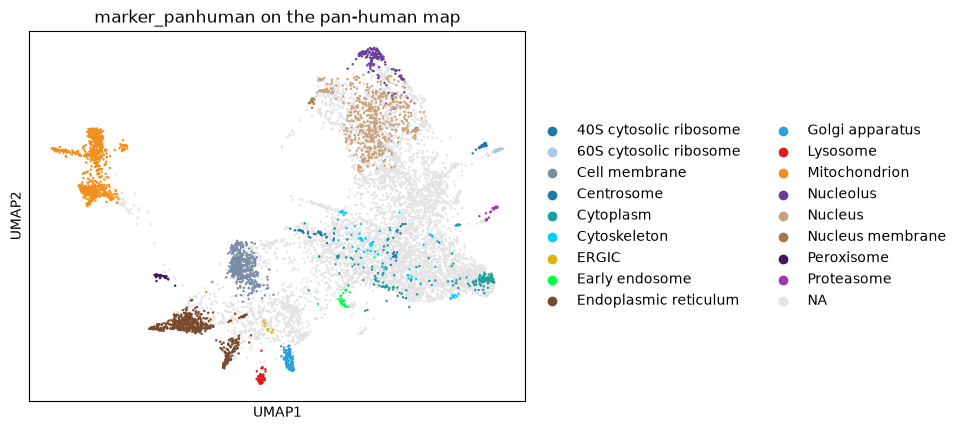

In [6]:
adata.obs[COLUMN] = pd.Categorical(markers)
gr.pp.set_sensible_compartment_colors(adata, columns=[COLUMN], plot_mapping=False, verbose=False)
sc.pl.umap(adata, color=COLUMN, size=12, na_color="#e3e3e3", title="marker_panhuman on the pan-human map")

## Write the column into `hsap_markers.tsv`

Existing rows keep their order and their other columns; marker proteins that are not in the
table yet are appended, sorted by accession.

In [ ]:
table = pd.read_csv(MARKER_FILE, sep="\t", dtype=str, index_col="id")
before = table.drop(columns=[COLUMN], errors="ignore")

new = markers.dropna().astype(str).rename(COLUMN)
order = list(before.index) + sorted(set(new.index) - set(before.index))
table = before.reindex(order).join(new)

pd.testing.assert_frame_equal(table.loc[before.index, before.columns], before)
table.to_csv(MARKER_FILE, sep="\t", index_label="id")
print(f"{MARKER_FILE}: {len(before)} -> {len(table)} rows, {table[COLUMN].notna().sum()} {COLUMN} entries")